# End-to-End Exploratory Data Analysis

## Online Retail Dataset

This project presents a complete and reproducible Exploratory
Data Analysis of the UCI Online Retail dataset.

### Project Objectives

- Understand the dataset and its business context.
- Assess data quality and investigate unusual observations.
- Explore numerical, categorical, and temporal variables.
- Investigate distributions and relationships.
- Identify meaningful business patterns.
- Communicate findings, limitations, and uncertainty.

### Observational Unit

Each row represents an invoice line item, not necessarily
an entire invoice or a unique customer.

### Data Source

UCI Machine Learning Repository — Online Retail

https://archive.ics.uci.edu/dataset/352/online+retail

## 1. Project Setup

Import the required libraries, locate the project directory,
define project paths, and prepare the output directories.

The notebook uses the project's local Python environment
managed by uv.

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns

from scipy import stats
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")


# --------------------------------------------------
# 1. Locate the project root
# --------------------------------------------------

def find_project_root(start: Path) -> Path:
    """
    Find the project root by locating pyproject.toml.
    """

    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )


PROJECT_ROOT = find_project_root(Path.cwd())


# --------------------------------------------------
# 2. Define project paths
# --------------------------------------------------

DATA_DIR = PROJECT_ROOT / "data"

RAW_DATA_DIR = DATA_DIR / "raw"
INTERIM_DATA_DIR = DATA_DIR / "interim"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
PROFILING_DIR = OUTPUT_DIR / "profiling"

REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

SOURCE_DIR = PROJECT_ROOT / "src"
CONFIG_DIR = PROJECT_ROOT / "config"
LOG_DIR = PROJECT_ROOT / "logs"


# --------------------------------------------------
# 3. Define dataset information
# --------------------------------------------------

DATASET_NAME = "Online Retail"

RAW_DATA_PATH = RAW_DATA_DIR / "Online Retail.xlsx"

DATASET_SHA256 = (
    "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d"
)


# --------------------------------------------------
# 4. Create required output directories
# --------------------------------------------------

OUTPUT_DIRECTORIES = [
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    TABLE_DIR,
    PROFILING_DIR,
    FIGURE_DIR,
    LOG_DIR,
]

for directory in OUTPUT_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 5. Verify the project environment and raw data
# --------------------------------------------------

if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Raw dataset not found: {RAW_DATA_PATH}"
    )


print("Project setup completed successfully.")
print("-" * 50)
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset      : {DATASET_NAME}")
print(f"Dataset path : {RAW_DATA_PATH}")
print(f"Dataset size : {RAW_DATA_PATH.stat().st_size:,} bytes")
print("-" * 50)

Project setup completed successfully.
--------------------------------------------------
Project root : d:\coding\eda\Part IX - Capstone
Dataset      : Online Retail
Dataset path : d:\coding\eda\Part IX - Capstone\data\raw\Online Retail.xlsx
Dataset size : 23,715,344 bytes
--------------------------------------------------


## 2. Visualization Convention

This project uses Matplotlib's object-oriented API exclusively.

Figures are created using matplotlib.figure.Figure, and Axes
are obtained through the Figure's subplots() method.

IPython's display() function is used to publish figures
immediately at the point of execution.

The pyplot API is not used anywhere in this project.

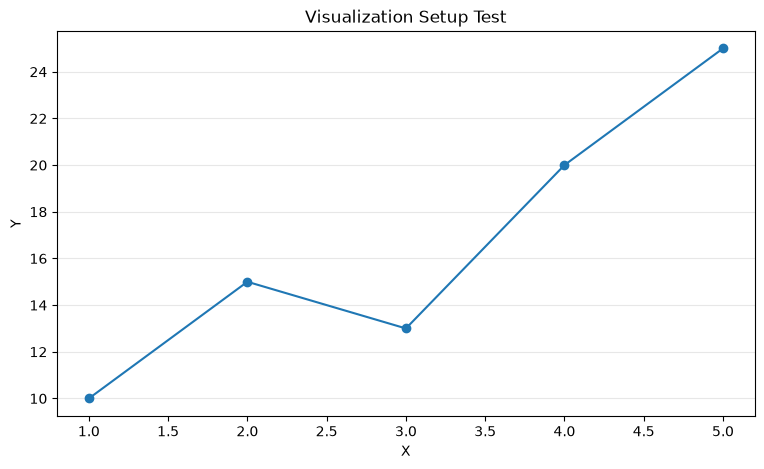

The next Python statement has executed.


In [23]:
fig = Figure(figsize=(9, 5))

ax = fig.subplots()

ax.plot(
    [1, 2, 3, 4, 5],
    [10, 15, 13, 20, 25],
    marker="o",
)

ax.set_title("Visualization Setup Test")
ax.set_xlabel("X")
ax.set_ylabel("Y")

ax.grid(axis="y", alpha=0.3)

# Render synchronously
fig.canvas.draw()

# Display immediately
display(fig)

print("The next Python statement has executed.")

## 3. Data Acquisition and Initial Inspection

Before conducting any analysis, we must establish that the
correct dataset has been acquired and loaded successfully.

This section covers:

1. Verifying the integrity of the original dataset.
2. Loading the Excel workbook into Pandas.
3. Inspecting its structure and dimensions.
4. Examining variable names and data types.
5. Reviewing initial observations.

The original dataset will remain unchanged. Any cleaning,
transformation, or derived data will be handled separately.

### 3.1 Data Integrity Verification

We use a SHA-256 checksum to verify that the local dataset
matches the file fingerprint recorded during acquisition.

This helps detect accidental modifications to the original
workbook.

In [24]:
import hashlib


def calculate_sha256(file_path: Path) -> str:
    """Calculate the SHA-256 checksum of a file."""

    sha256 = hashlib.sha256()

    with file_path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


actual_sha256 = calculate_sha256(RAW_DATA_PATH)

print("Expected SHA-256:", DATASET_SHA256)
print("Actual SHA-256:  ", actual_sha256)

if actual_sha256 != DATASET_SHA256:
    raise ValueError(
        "Dataset integrity verification failed. "
        "The original dataset may have been modified."
    )

print("\nDataset integrity verified successfully.")


Expected SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Actual SHA-256:   43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d

Dataset integrity verified successfully.


### 3.2 Loading the Dataset

We will load the original Excel workbook using Pandas.

Identifier columns will initially be represented as strings.
Identifiers are labels, not numerical measurements, even when
their values contain digits.

We will not perform any cleaning at this stage.

In [25]:
df = pd.read_excel(
    RAW_DATA_PATH,
    sheet_name="Online Retail",
    engine="openpyxl",
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


Dataset loaded successfully.
Shape: 541,909 rows × 8 columns


### 3.3 Structural Inspection

We begin with a structural overview before examining individual
variables or calculating statistics.

The inspection includes:

- Dataset dimensions.
- Column names.
- Data types.
- Non-null counts.
- Memory usage.

In [26]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
display(pd.Index(df.columns))

print("\nDataFrame information:")
df.info(memory_usage="deep")


Dataset shape: (541909, 8)

Column names:


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(1), string(3)
memory usage: 168.2 MB


### 3.4 Initial Observations

We inspect a few records to understand how observations are
represented.

At this stage, we are looking for structural clues, not making
conclusions about the dataset.

In [28]:
print("First five observations:")
display(df.head())

print("Last five observations:")
display(df.tail())

print("Five randomly selected observations:")
display(df.sample(n=5, random_state=42))

First five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Last five observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


Five randomly selected observations:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502,United Kingdom


### 3.5 Variable Inventory

A variable inventory provides an initial overview of the
dataset's columns, their data types, and their non-null counts.

We will extend this inventory later with semantic types,
missingness percentages, uniqueness, and quality assessments.

In [29]:
variable_inventory = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_percentage": (
        df.isna().mean().mul(100).values
    ),
    "unique_count": df.nunique(dropna=True).values,
})

variable_inventory = variable_inventory.sort_values(
    "missing_percentage",
    ascending=False,
    ignore_index=True,
)

display(variable_inventory)

,column,dtype,non_null_count,missing_count,missing_percentage,unique_count
0,CustomerID,string,406829,135080,24.926694,4372
1,Description,object,540455,1454,0.268311,4223
2,StockCode,string,541909,0,0.000000,4070
3,InvoiceNo,string,541909,0,0.000000,25900
4,Quantity,int64,541909,0,0.000000,722
5,InvoiceDate,datetime64[us],541909,0,0.000000,23260
6,UnitPrice,float64,541909,0,0.000000,1630
7,Country,str,541909,0,0.000000,38


In [30]:
inventory_path = TABLE_DIR / "initial_variable_inventory.csv"

variable_inventory.to_csv(
    inventory_path,
    index=False,
)

print("Variable inventory saved to:")
print(inventory_path)

Variable inventory saved to:
d:\coding\eda\Part IX - Capstone\outputs\tables\initial_variable_inventory.csv


## 4. Data Quality Assessment

Before conducting detailed exploratory analysis, we need to evaluate the
reliability and consistency of the dataset.

Data quality issues can distort statistical summaries, visualizations,
and business interpretations. Therefore, this section investigates
duplicate records, missing values, unusual numerical values, transaction
anomalies, temporal validity, and categorical inconsistencies.

The original dataset will remain unchanged throughout this investigation.
All identified issues will be documented before deciding how they should
be handled in subsequent analyses.

### 4.1 Duplicate Records

Duplicate records may inflate transaction counts, quantities, and
transaction values.

We will investigate both:

- **Exact duplicate rows:** Records where every column has an identical
  value.
- **Potential transaction-line duplicates:** Records sharing the same
  invoice number, stock code, description, quantity, unit price,
  customer, and invoice date.

An exact duplicate is not automatically proof of an erroneous record.
We must consider the dataset's observational unit and transaction
structure before deciding how to handle duplicates.

In [31]:
exact_duplicate_mask = df.duplicated(keep=False)
exact_duplicate_count = df.duplicated().sum()

print(f"Total records: {len(df):,}")
print(f"Exact duplicate rows beyond first occurrences: {exact_duplicate_count:,}")
print(f"Records involved in duplicate groups: {exact_duplicate_mask.sum():,}")

if exact_duplicate_count > 0:
    print("\nSample duplicate records:")
    display(
        df.loc[exact_duplicate_mask]
        .sort_values(by=df.columns.tolist())
        .head(10)
    )

Total records: 541,909
Exact duplicate rows beyond first occurrences: 5,268
Records involved in duplicate groups: 10,147

Sample duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom


### 4.2 Missing Values

Missing values can reduce the usable sample size and introduce bias,
particularly when their occurrence is not random.

We will examine:

- Missing-value counts and percentages.
- Missingness patterns across variables.
- Whether records with missing customer identifiers still contain
  useful transaction information.

Missing values will not be automatically removed. Their treatment
depends on the analytical question and the role of each variable.

In [32]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100),
    "non_missing_count": df.notna().sum(),
})

missing_summary = (
    missing_summary
    .sort_values("missing_percentage", ascending=False)
    .reset_index(names="column")
)

display(missing_summary)

,column,missing_count,missing_percentage,non_missing_count
0,CustomerID,135080,24.926694,406829
1,Description,1454,0.268311,540455
2,StockCode,0,0.000000,541909
3,InvoiceNo,0,0.000000,541909
4,Quantity,0,0.000000,541909
5,InvoiceDate,0,0.000000,541909
6,UnitPrice,0,0.000000,541909
7,Country,0,0.000000,541909


In [33]:
missing_patterns = (
    df.isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

missing_patterns["percentage"] = (
    missing_patterns["record_count"] / len(df) * 100
)

display(missing_patterns)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,record_count,percentage
0,False,False,False,False,False,False,False,False,406829,75.073306
1,False,False,False,False,False,False,True,False,133626,24.658384
2,False,False,True,False,False,False,True,False,1454,0.268311
